# Olympic Trends and Insights - Final Project

#### Team Members:
- Linh Ngoc Pham
- Krishna M Patel
- Diego A Martinez
- Jose F Rodriguez

## Introduction


The Olympic Games have, for over a century, embodied the pinnacle of athletic excellence and served as a mirror reflecting the social, political, and cultural circumstances of their times. By exploring various characteristics of the Olympics and tracking their evolution, we can observe the echoes of significant societal changes such as population growth, the rise and fall of countries' global importance, and progress toward gender equality in sports.

In this project, we aim to analyze historical Olympic data from 1896 to 2016 to better understand these transformations and answer the following key questions:

1) How has the number of medals won by different countries changed over time? What trends can be observed?

2) What is the gender proportion among athletes, and how does it vary across sports and over time? Are there 
       noticeable trends?

3) How is the number of athletes distributed across different sports?

4) What is the optimal age for success in various sports, and how does this vary across different athletic 
       disciplines?

By addressing these questions, we hope to gain insights into how the Olympics have evolved in relation to global demographic shifts, the increasing representation of women in sports, and the factors that contribute to athletic success across different disciplines. This information can help stakeholders, such as sports organizations, policymakers, and event organizers, make informed decisions to enhance performance, improve inclusivity, and allocate resources effectively. Additionally, clear visualizations and findings can engage and educate a broader audience, making the history and evolution of the Olympics more engaging.

## Methodology

We will use Python packages such as Pandas, Matplotlib, Seaborn, and Statsmodels to import, clean, analyze, and visualize the data. The combined use of these packages, along with Python's base tools, will enable us to efficiently handle the dataset, which is originally in CSV format. We will begin by identifying missing and abnormal data, analyzing the causes of these issues, and determining the best approach to address them while maintaining the integrity of the dataset. Once the data is cleaned, we will apply statistical modeling to identify trends and draw meaningful conclusions from the information. Additionally, we will use visualizations to illustrate these trends and provide a more intuitive and accessible understanding of the answers to the questions posed.

## Required Packages

In [7]:
try:
    import pandas as pd
except ImportError:
    import pip
    pip.main(['install', 'pandas'])
    import pandas as pd
try:
    import matplotlib.pyplot as plt
except ImportError:
    import pip
    pip.main(['install', 'matplotlib.pyplot'])
    import matplotlib.pyplot as plt
try:
    import seaborn as sns
except ImportError:
    import pip
    pip.main(['install', 'seaborn'])
    import seaborn as sns
try:
    import statsmodels.api as sm
except ImportError:
    import pip
    pip.main(['install', 'statsmodels.api'])
    import statsmodels.api as sm

- `Pandas` is a library designed to work with data sets. It provides the necessay functions to import, explorr, clean and analyze the Olympics data set.
- `Seaborn` (sns) is a data visualiztion library that simplifies the creation of informative and statistical graphics. 
- `Matplotlib` (plt) is a plotting library that provides a foundation for creating static, animated, and interactive visualizations.
- `statsmodels.api'` is a Python library used for performing statistical modeling, hypothesis testing, and data exploration with detailed output for interpreting results.

## Data Preparation

The dataset is a historical record of the modern Olympic Games, spanning from Athens 1896 to Rio 2016. It was obtained from the following repository:

- 120 Years of Olympic History: Athletes and Results on Kaggle (https://www.kaggle.com/datasets/heesoo37/120- years-of-olympic-history-athletes-and-results/)

This dataset contains 271,116 rows and 15 columns, with each row representing an individual athlete competing in a specific Olympic event. The variables included in the dataset are:

- ID: Unique identifier for each athlete
- Name: Athlete's name
- Sex: Gender (M or F)
- Age: Athlete's age (integer)
- Height: Athlete's height (in centimeters)
- Weight: Athlete's weight (in kilograms)
- Team: Name of the athlete's team
- NOC: National Olympic Committee 3-letter code
- Games: Year and season of the Olympic event
- Year: Year of the Olympic Games
- Season: Whether the Games are Summer or Winter
- City: Host city of the Olympic Games
- Sport: The sport the athlete competed in
- Event: The specific event within the sport
- Medal: Type of medal won (Gold, Silver, Bronze, or NA if no medal was won)

The primary purpose of this dataset is to illustrate the evolution of the Olympic Games over time, with a particular focus on the participation and performance of athletes from various nations and the increasing involvement of women in different sports and events.

In [11]:
olympics = pd.read_csv("olympics.csv")
olympics.head(2)

,id,name,sex,age,height,weight,team,noc,games,year,season,city,sport,event,medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN


In [12]:
olympics.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 271116 entries, 0 to 271115
Data columns (total 15 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   id      271116 non-null  int64  
 1   name    271116 non-null  object 
 2   sex     271116 non-null  object 
 3   age     261642 non-null  float64
 4   height  210945 non-null  float64
 5   weight  208241 non-null  float64
 6   team    271116 non-null  object 
 7   noc     271116 non-null  object 
 8   games   271116 non-null  object 
 9   year    271116 non-null  int64  
 10  season  271116 non-null  object 
 11  city    271116 non-null  object 
 12  sport   271116 non-null  object 
 13  event   271116 non-null  object 
 14  medal   39783 non-null   object 
dtypes: float64(3), int64(2), object(10)
memory usage: 31.0+ MB


In [13]:
# Number of missing values for each variable and its corresponding percentage
missing_values = olympics.isna().sum()
missing_olympics = (olympics.isna().sum() / len(olympics)) * 100
missing_table = pd.DataFrame({'Missing Values': missing_values,
                                   'Percentage Missing': missing_olympics})
missing_table.sort_values(by='Missing Values', ascending=False, inplace=True)
print(missing_table)

        Missing Values  Percentage Missing
medal           231333           85.326207
weight           62875           23.191180
height           60171           22.193821
age               9474            3.494445
id                   0            0.000000
name                 0            0.000000
sex                  0            0.000000
team                 0            0.000000
noc                  0            0.000000
games                0            0.000000
year                 0            0.000000
season               0            0.000000
city                 0            0.000000
sport                0            0.000000
event                0            0.000000


The table summarizes the number and percentage of missing values in the dataset. The medal variable has the highest percentage of missing data (over 85%), which is expected since it includes athletes who did not win a medal. Other variables, such as weight and height, have 23% and 22% missing data, respectively, potentially due to incomplete records. However, these variables are not essential for addressing the research questions proposed for this project and can be dismissed. All other key variables, including identifiers and categorical data, have no missing values, ensuring the dataset's overall reliability for analysis.

In [15]:
print(f"Variables of Sex are:\n {olympics['sex'].unique()}")
print(f"Variables of Season are:\n {olympics['season'].unique()}")
print(f"Variables of Medal are:\n {olympics['medal'].unique()}")
print(f"Variables of Sport are:\n {olympics['sport'].unique()}")

Variables of Sex are:
 ['M' 'F']
Variables of Season are:
 ['Summer' 'Winter']
Variables of Medal are:
 [nan 'Gold' 'Bronze' 'Silver']
Variables of Sport are:
 ['Basketball' 'Judo' 'Football' 'Tug-Of-War' 'Speed Skating'
 'Cross Country Skiing' 'Athletics' 'Ice Hockey' 'Swimming' 'Badminton'
 'Sailing' 'Biathlon' 'Gymnastics' 'Art Competitions' 'Alpine Skiing'
 'Handball' 'Weightlifting' 'Wrestling' 'Luge' 'Water Polo' 'Hockey'
 'Rowing' 'Bobsleigh' 'Fencing' 'Equestrianism' 'Shooting' 'Boxing'
 'Taekwondo' 'Cycling' 'Diving' 'Canoeing' 'Tennis' 'Modern Pentathlon'
 'Figure Skating' 'Golf' 'Softball' 'Archery' 'Volleyball'
 'Synchronized Swimming' 'Table Tennis' 'Nordic Combined' 'Baseball'
 'Rhythmic Gymnastics' 'Freestyle Skiing' 'Rugby Sevens' 'Trampolining'
 'Beach Volleyball' 'Triathlon' 'Ski Jumping' 'Curling' 'Snowboarding'
 'Rugby' 'Short Track Speed Skating' 'Skeleton' 'Lacrosse' 'Polo'
 'Cricket' 'Racquets' 'Motorboating' 'Military Ski Patrol' 'Croquet'
 'Jeu De Paume' 'Roque

In [16]:
#Dropping NA values
olympics_cleaned = olympics.dropna()

### 1. How has the number of medals won by different countries changed over time? What trends can be observed?

In [18]:
#Data Preparation
# Selects non-missing observations for Summer olympics only
medalists = olympics[olympics['medal'].notna()]
medalists = medalists[medalists['season']=='Summer']
#Groups by year to count the number of countries participating
total_medals_year = medalists.groupby('year').size()
countries_per_year = olympics[olympics['season']=='Summer'].groupby('year')['noc'].nunique().reset_index(name='num_countries')
#Groups by country to count number of medals per country in total
total_medals = medalists.groupby(by='noc').size().reset_index(name = 'Total Medals')
total_medals = total_medals.sort_values(by='Total Medals', ascending = False).head(12).reset_index(drop=True)
#Selects the countries with most number of medals
top12 = medalists[medalists['noc'].isin(total_medals['noc'])]
top12 = top12.groupby(['year','noc']).size().reset_index(name = 'medals')
#Creates Data frame for top coutries to measure the proportion of medals per event
total_medal_year = pd.DataFrame(medalists.groupby('year').size())
total_medal_year = total_medal_year.reset_index(names = 'year')
total_medal_year.columns = ['year','year_medals']
prop_by_year =  pd.merge( left = top12, right = total_medal_year, on = 'year', how = 'outer')
prop_by_year = prop_by_year.assign( proportion = prop_by_year['medals']/prop_by_year['year_medals'])
#The data is being grouped both by year and noc to measure number of participants per country per event
grouped = prop_by_year.groupby(['year', 'noc'])
result = grouped['proportion'].sum().reset_index()
prop_by_year_sorted = prop_by_year.sort_values(by=['year', 'proportion'], ascending=[True, False])
top10_by_year = prop_by_year_sorted.groupby('year').head(10).reset_index(drop=True)
pivot_top = top10_by_year.pivot(index='year', columns='noc', values='proportion').fillna(0)
summer_olympics = olympics[olympics['season'] == 'Summer']
participants = summer_olympics.groupby(['year', 'noc']).size().reset_index(name='participants')
medals = medalists.groupby(['year', 'noc']).size().reset_index(name='medals')
participant_medals = pd.merge(participants, medals, on=['year', 'noc'], how='outer').fillna(0)

# This code analyzes the performance and participation trends in the Summer Olympics, focusing on medal 
# distribution and country-level contributions. It filters the dataset to include only medal-winning athletes 
# and calculates metrics such as the total number of medals per year, participating countries, and the top 12 
# medal-winning countries. Proportions of medals won by top-performing countries across years are computed and 
# visualized. Additionally, the relationship between the number of participants and medals won is examined 

### Change of number of countries and number of medalist by Event

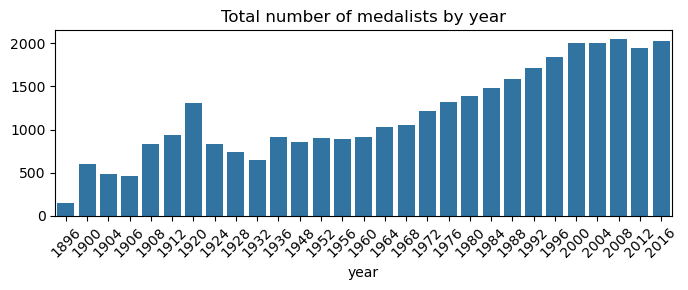

In [20]:
plt.figure(figsize=(7, 3))
sns.barplot(data=total_medals_year)
plt.title('Total number of medalists by year')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

- The number of medalists in the Summer Olympics steadily increased over time, driven by the growing number of sports and events. However, the 1920 Summer Olympics experienced an exceptional spike in medalists, likely due to the post-World War I resurgence and an expanded event lineup aimed at revitalizing the Olympic movement. This surge was followed by a decline in subsequent years as the program stabilized.
- The 1906 Intercalated Games in Athens aimed to revive the Olympics after the poorly received 1900 and 1904 events. Though they boosted interest and set organizational standards, they were later excluded from the official Olympic roster for not aligning with the 4-year cycle.
- The 1916, 1940, and 1944 Olympics were canceled due to the global conflicts of World War I (1914–1918) and World War II (1939–1945).


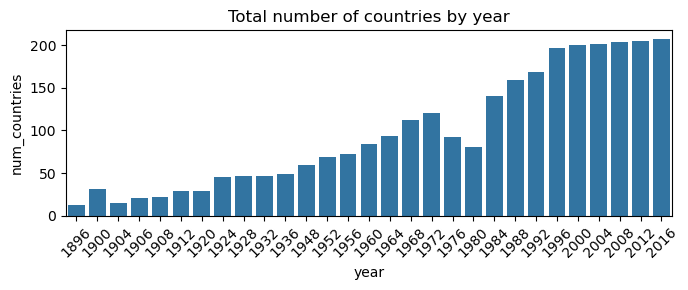

In [22]:
plt.figure(figsize=(7, 3))
sns.barplot(data=countries_per_year, x='year', y='num_countries')
plt.title('Total number of countries by year')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


- The number of countries participating in each Summer Olympics steadily increased as the Games grew in popularity and the world became more interconnected. However, participation dropped in 1976 and 1980 due to political boycotts.
- In 1976, 29 countries, primarily from Africa, boycotted the Montreal Games after the IOC refused to ban New Zealand for its rugby team's tour of apartheid-era South Africa, which violated a United Nations call for a sporting embargo.
- In 1980, participation fell further as 66 countries, led by the United States, boycotted the Moscow Games in protest of the Soviet Union's invasion of Afghanistan. This resulted in only 80 nations competing, the lowest since 1956.

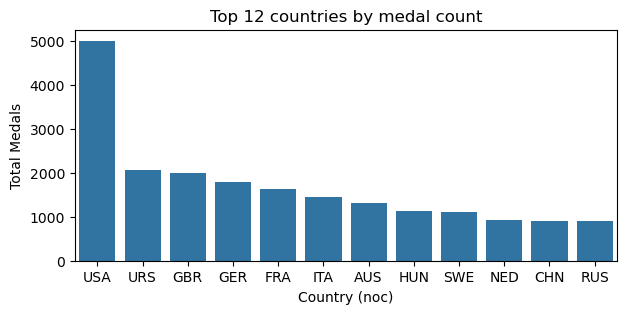

In [24]:
plt.figure(figsize=(7, 3))
sns.barplot(data = total_medals, x = 'noc', y = 'Total Medals') 
plt.title("Top 12 countries by medal count")
plt.xlabel('Country (noc)')
plt.show()

- The barplot displays the top 12 countries with the highest total medal counts across all years. Historical and geographical factors play a significant role in these rankings, including the periods of activity for the USSR and Russia, among others. 

    1. USA
    2. URS (Soviet Union)
    3. GBR (Great Britain)
    4. GER (Germany)
    5. FRA (France)
    6. ITA (Italy)
    7. AUS (Australia)
    8. HUN (Hungary)
    9. SWE (Sweden)
    10. NED (Netherlands)
    11. CHN (China)
    12. RUS (Russia)


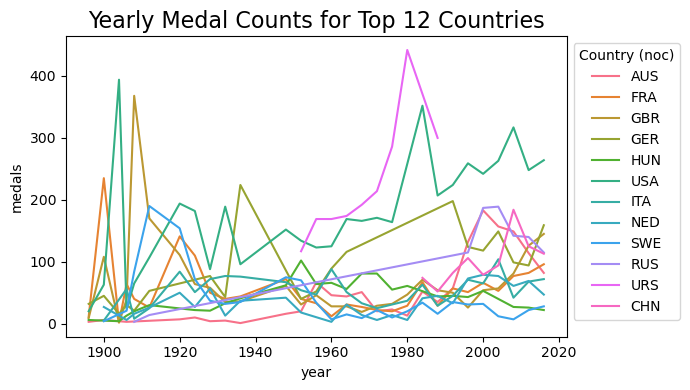

In [26]:
plt.figure(figsize=(7, 4))
sns.lineplot(data = top12, x = 'year', y = 'medals', hue = 'noc')
plt.title("Yearly Medal Counts for Top 12 Countries", fontsize=16)
plt.legend(title="Country (noc)", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

- The line plot shows the yearly medal counts for the top 12 countries in the history of the Summer Olympics. It highlights fluctuations in medal performance over time, with noticeable peaks for certain countries like the USSR and the USA during specific periods. Historical factors such as the Cold War, boycotts, and changes in the number of events likely influenced these trends. The data also reflects periods of dominance by specific nations, such as China's rise in recent decades.

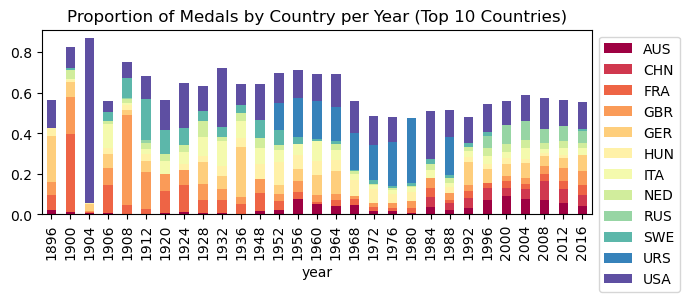

In [28]:
pivot_top.plot(kind='bar', stacked=True, figsize=(7, 3), colormap='Spectral')
plt.title("Proportion of Medals by Country per Year (Top 10 Countries)")
plt.legend(bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

- This stacked bar plot shows the proportion of medals won by the top 10 countries in each Olympic year. Each bar represents the total proportion of medals for that year, broken down by the contributions of the top-performing countries. Over time, the shrinking height of the bars indicates that countries outside the top 10 are increasingly winning medals, reflecting a growing diversity in global athletic success. Notably, the dominance of certain countries like the USA and USSR during specific periods is evident, with their proportions decreasing as other nations improve their performances in later years
- The 1904 Summer Olympics, held in St. Louis, saw minimal international participation, with only 69–74 athletes from outside North America out of 651 total competitors and representation from just 12–15 nations. Travel difficulties and tensions from the Russo-Japanese War further limited participation, resulting in a competition largely dominated by the United States.

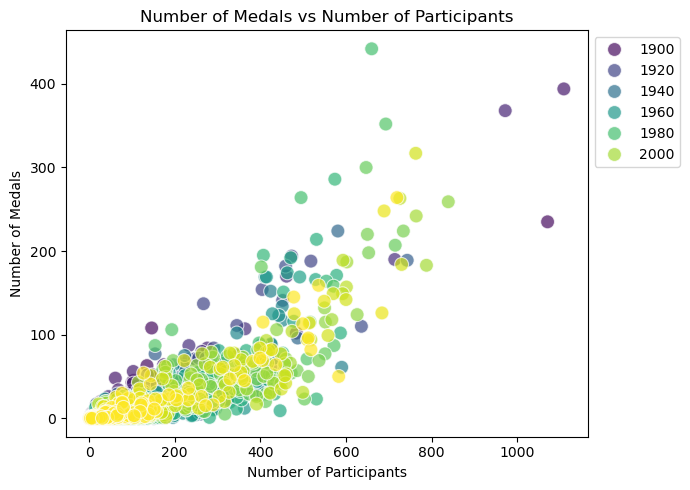

In [30]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=participant_medals, x='participants', y='medals', hue='year', palette='viridis', s=100, alpha=0.7)
plt.title("Number of Medals vs Number of Participants")
plt.xlabel("Number of Participants")
plt.ylabel("Number of Medals")
plt.legend(bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

This scatterplot displays the relationship between the number of participants and the number of medals won by countries in the Summer Olympics over different years. Each point represents a country in a specific year, with the color indicating the year. The plot shows a general positive correlation: countries with more participants tend to win more medals. Outliers, such as points with high medal counts relative to participants or vice versa, likely represent dominant countries or specific historical contexts.

#### Regression Model

We used a simple linear regression model, implemented through the `statsmodels.api` package, to analyze the relationship between the number of participants and the number of medals won by countries in the Summer Olympics. Linear regression was chosen because it captures the strength of the relationship between these variables and provides interpretable metrics, such as coefficients and R-squared values, to measure the model's performance.

The primary goal of this analysis was to understand how the number of participants influences a country's success in winning medals. By examining this relationship, we aimed to determine how much of the variation in medal counts can be explained by participation and whether increasing participation significantly impacts success. 

                            OLS Regression Results                            
Dep. Variable:                 medals   R-squared:                       0.718
Model:                            OLS   Adj. R-squared:                  0.718
Method:                 Least Squares   F-statistic:                     7140.
Date:                Sun, 08 Dec 2024   Prob (F-statistic):               0.00
Time:                        02:28:37   Log-Likelihood:                -12159.
No. Observations:                2810   AIC:                         2.432e+04
Df Residuals:                    2808   BIC:                         2.433e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const           -5.5684      0.404    -13.774   

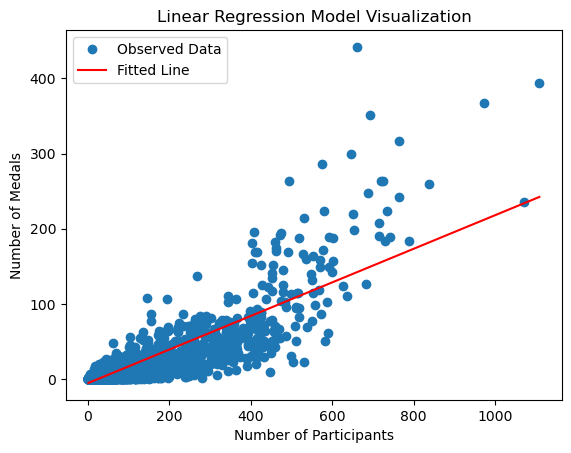

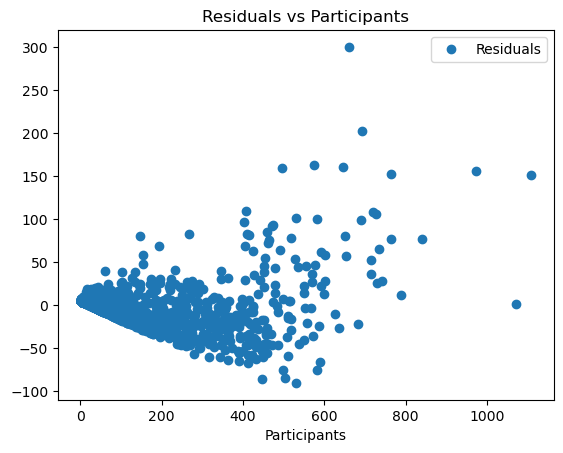

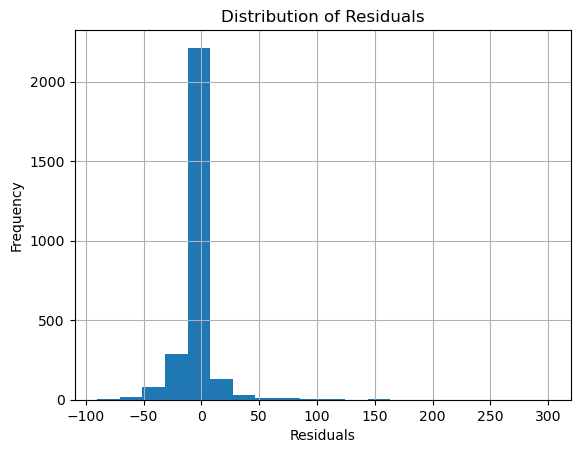

In [34]:
X = participant_medals[['participants']]  
y = participant_medals['medals']          
X = sm.add_constant(X)
model = sm.OLS(y, X).fit()
print(model.summary())

y_pred = model.predict(X)
plot_df = pd.DataFrame({"Participants": X['participants'], "Actual Medals": y, "Predicted Medals": y_pred})
ax = plot_df.plot(x='Participants', y='Actual Medals', style='o', label='Observed Data')
plot_df.sort_values('Participants', inplace=True)
plot_df.plot(x='Participants', y='Predicted Medals', kind='line', ax=ax, label='Fitted Line', color='red')
ax.set_title('Linear Regression Model Visualization')
ax.set_xlabel('Number of Participants')
ax.set_ylabel('Number of Medals')

residuals = y - y_pred
plot_df['Residuals'] = residuals
plot_df.plot(x='Participants', y='Residuals', style='o', title='Residuals vs Participants')

plt.figure()
residuals.hist(bins=20)
plt.title('Distribution of Residuals')
plt.xlabel('Residuals')
plt.ylabel('Frequency')
plt.show()


The regression demonstrates a strong positive relationship between the number of participants and the number of medals, with 71.8% of the variation in medal counts explained by the number of participants. On average, each additional participant is associated with approximately 0.22 more medals. The residuals are centered around zero, indicating that the model fits the data reasonably well. However, there is evidence of increasing variation in residuals as the number of participants increases, and a slight curvature suggests that the relationship may not be entirely linear. While the model effectively captures the connection between participation and medal success, addressing these limitations through transformations or the inclusion of additional predictors could enhance its performance.

### 2. What is the gender proportion among athletes, and how does it vary across sports, medals, and over time? Any trends?

In [37]:
#Number of females and males across the year
gender_over_time = olympics.groupby(['year', 'sex']).size().reset_index(name='Count')
#Total number of participants across the year
gender_over_time_total = gender_over_time.groupby('year')['Count'].transform('sum')
#Proportion of female and male participants across the year
gender_over_time['Proportion'] = gender_over_time['Count'] / gender_over_time_total
#Total participants by sex
total_gender= olympics['sex'].value_counts()
#Count of number of participants by sports and sex
gender_sport = olympics.groupby(['sex','sport']).size().reset_index(name='Count')
##Proportion of participants by sports and sex
gender_sport_total = gender_sport.groupby('sport')['Count'].transform('sum')
gender_sport['Proportion']= gender_sport['Count']/gender_sport_total
city_grouped_data = olympics_cleaned.groupby(["city"])
gender_dict = dict()
for i,j in city_grouped_data:
    gender_dict[j.year.max()]=dict()
    gender_data = j.groupby(['sex'])
    for k,l in gender_data:
        gender_dict[j.year.max()][k]=dict()
        if k == 'M':
            medal_data = l.groupby(['medal'])
            for m,n in medal_data:
                gender_dict[j.year.max()][k][m]=len(n)
        else:
            medal_data = l.groupby(['medal'])
            for m,n in medal_data:
                gender_dict[j.year.max()][k][m]=len(n)          
data = []
for year, gender_data in gender_dict.items():
    for gender, medal_counts in gender_data.items():
        total_medals = sum(medal_counts.values())
        data.append({'Year': year, 'Gender': gender, 'Total_Medals': total_medals})
# Create the DataFrame
total_gender_medals = pd.DataFrame(data)
total_gender_medals['Gender'] = total_gender_medals['Gender'].str[0]  # Extract 'M' or 'F' from tuples
total_gender_medals_sorted = total_gender_medals.sort_values('Year')

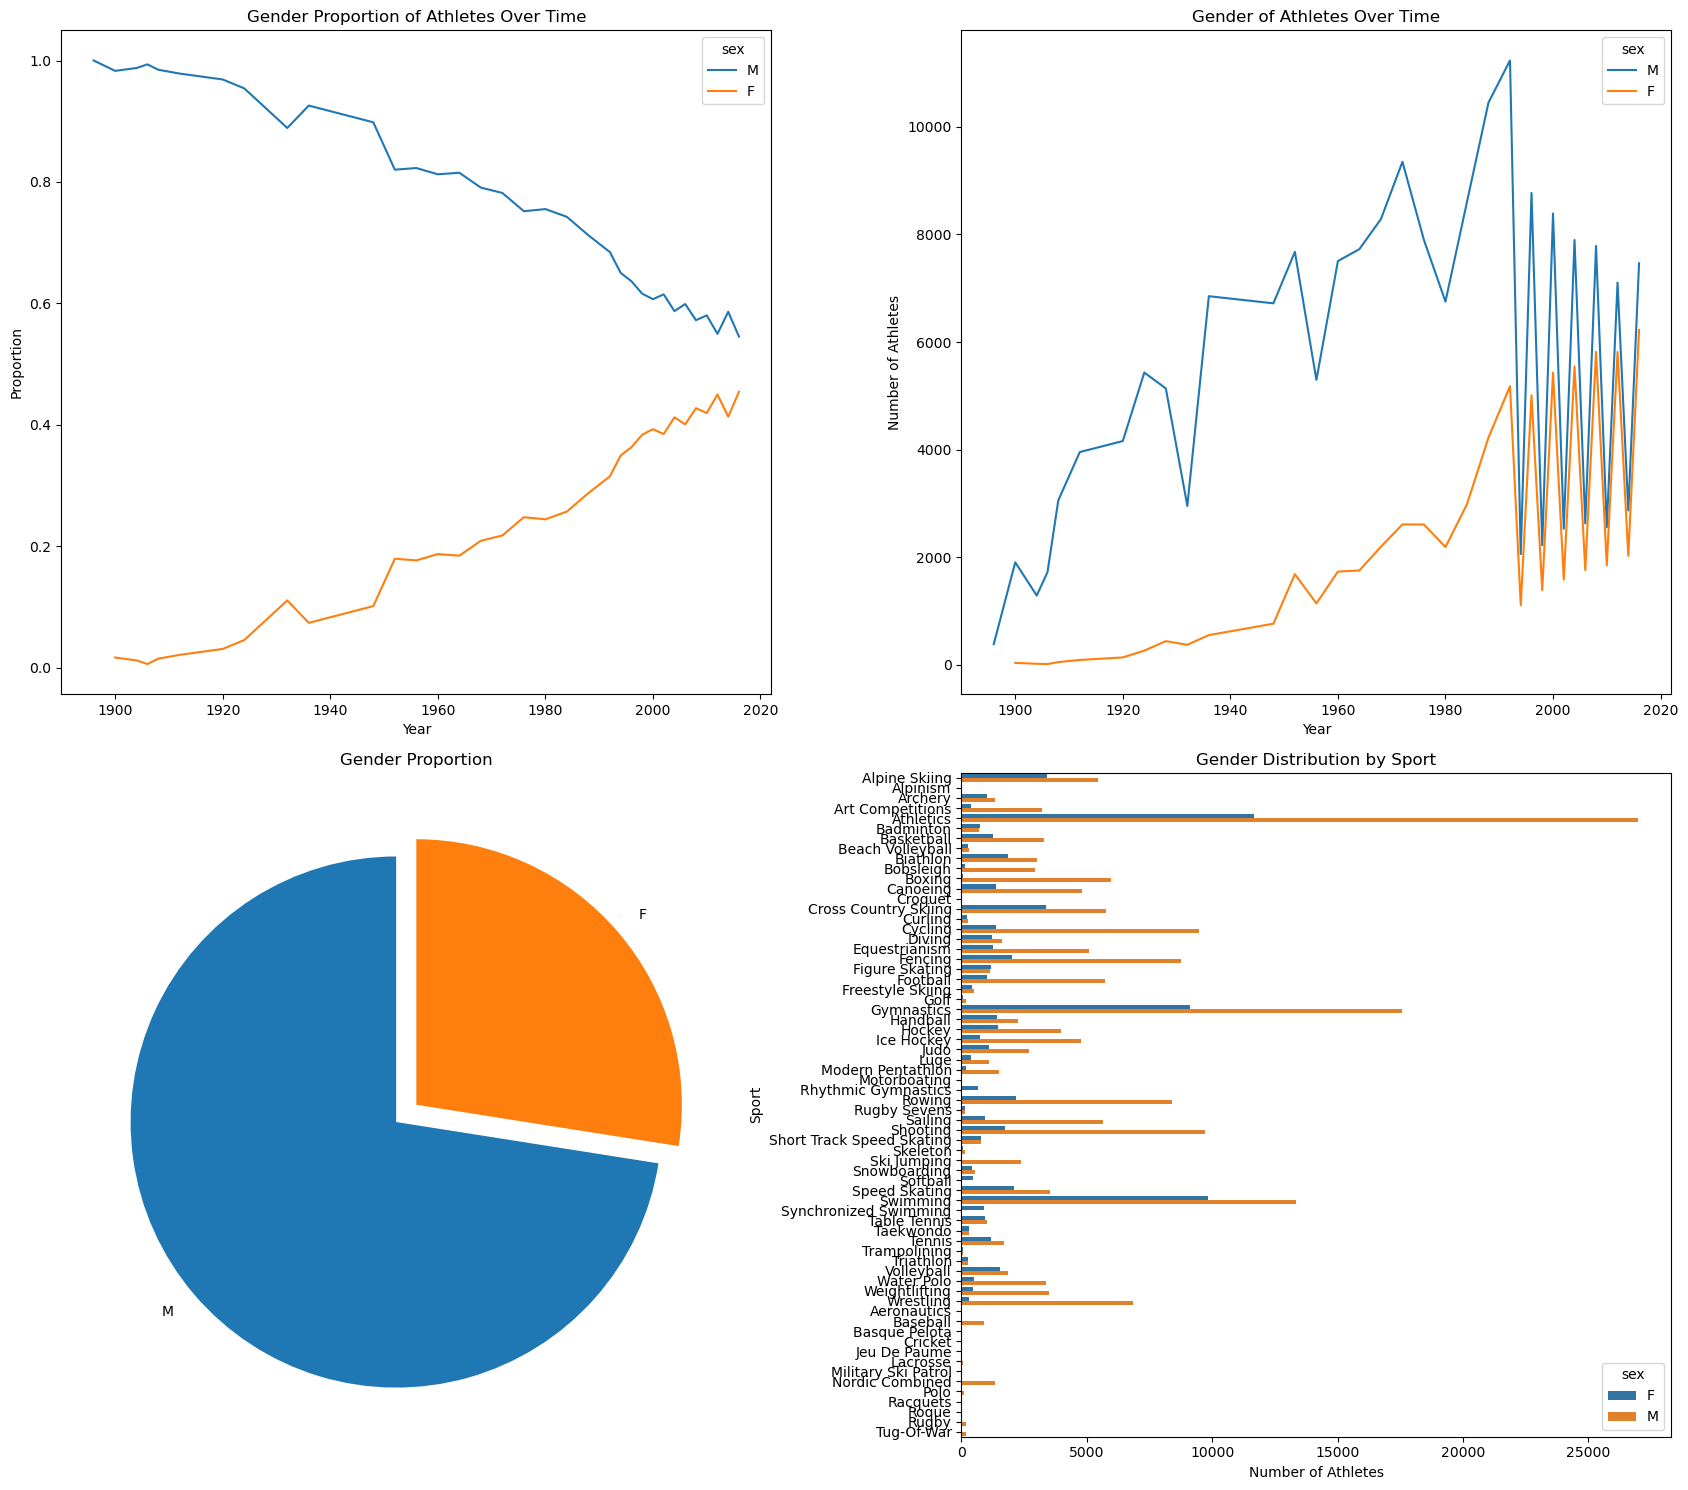

In [38]:
fig, ax = plt.subplots(2, 2, figsize=(17, 15))

sns.lineplot(data=gender_over_time, x='year', y='Proportion', hue='sex', ax=ax[0, 0])
ax[0,0].set_title('Gender Proportion of Athletes Over Time')
ax[0,0].set_ylabel('Proportion')
ax[0,0].set_xlabel('Year')

sns.lineplot(data=gender_over_time, x='year', y='Count', hue='sex', ax=ax[0, 1])
ax[0,1].set_title('Gender of Athletes Over Time')
ax[0,1].set_ylabel('Number of Athletes')
ax[0,1].set_xlabel('Year')

ax[1, 0].pie(total_gender, labels=total_gender.index, startangle=90, explode=(0.1, 0), shadow=False)
ax[1, 0].set_title('Gender Proportion')

sns.barplot(data=gender_sport, x='Count',y='sport',hue='sex', ax=ax[1, 1])
ax[1,1].set_title('Gender Distribution by Sport')
ax[1,1].set_xlabel('Number of Athletes')
ax[1,1].set_ylabel('Sport')

plt.tight_layout()
plt.show()

#### Observations: 

From 1896 to 2016, the trend in gender representation at the Olympic Games evolved significantly, reflecting broader social and political shifts, as well as changes in Olympic policies.

1. Early Years (1896-1930s):
The first modern Olympic Games in 1896 were overwhelmingly male-dominated, with women’s participation being almost nonexistent. Only men were allowed to compete in most events, with a few exceptions.
Women were excluded from many major sports, and there was a general societal belief that they were physically incapable of competing at the same level as men. This was compounded by the social norms of the time, which limited women's roles in public life, including in sports.

3. Post-World War I and Women's Inclusion (1920s-1940s):
1920s-1930s: Women's participation began to increase, though it was still limited. The 1928 Amsterdam Games were a turning point, where women were first allowed to compete in track and field events (with a limited number of events).
1940s-1950s: During this period, women’s events expanded slowly, but male athletes continued to dominate both in number and in overall medal tallies. Socially, the role of women in sports was still a subject of debate, and participation was limited by cultural and political factors.
   
5. Post-1960s: The Rise of Women's Sports and Feminist Movements (1960s-1980s):
1960s: The rise of feminist movements and increasing calls for gender equality led to significant policy changes in the Olympics. The 1960 Rome Games were the first Olympics where women competed in gymnastics, and the trend toward gender inclusivity continued.
1970s: Major changes, such as the introduction of Title IX in the United States (1972), a law that mandated equal opportunities for women in sports, contributed to greater female participation in the Olympics. The 1972 Munich Games marked a major turning point, as more female athletes competed in the Olympics than ever before.
1980s: The number of women’s events increased, and women began to medal in previously male-dominated sports like track and field, swimming, and rowing. The 1980s also saw an increase in sports such as women’s soccer, which would become a significant Olympic event in later years.
   
7. 1990s: Further Expansion of Women's Events (1990s-2000s):
The 1990s saw the inclusion of more female events, including women's pole vault and triple jump, as well as more representation in team sports like basketball and soccer. By 1996, the Atlanta Games featured a large number of women athletes, and the International Olympic Committee (IOC) began pushing for gender equity in event offerings.
Notable achievements during this period include women breaking records in athletics, gymnastics, and swimming, showing that they could compete at the same level as men. However, the overall number of female athletes was still low compared to male athletes.

9. 2000-2016: Achieving Gender Balance and Social Change:
2000s: The turn of the century brought notable changes, with the gender gap in the number of athletes steadily decreasing. 
2016 Rio Olympics: For the first time in Olympic history, women’s participation reached close to 50%, with female athletes making up 45.6% of the total participants, marking a major milestone in gender equality.
The ratio of male athletes declined slightly, as the IOC increasingly emphasized gender balance in competition. However, while female participation grew, the distribution of athletes across different sports remained uneven, with women still being underrepresented in some fields, like weightlifting and wrestling, where men still dominated.

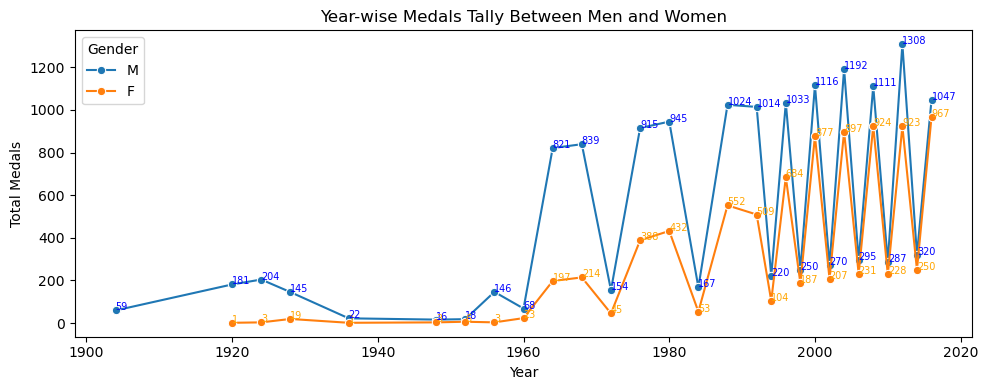

In [40]:
# Set up the plot
plt.figure(figsize=(10, 4))

# Plot lines for men and women
sns.lineplot(
    data=total_gender_medals_sorted,
    x='Year', y='Total_Medals', hue='Gender', 
    marker='o', linestyle='-'
)

# Annotate points
for _, row in total_gender_medals_sorted.iterrows():
    plt.annotate(f"{row['Total_Medals']}", xy=(row['Year'], row['Total_Medals']), 
                 color='blue' if row['Gender'] == 'M' else 'orange', fontsize=7)
plt.title('Year-wise Medals Tally Between Men and Women')
plt.xlabel('Year')
plt.ylabel('Total Medals')
plt.legend(title='Gender', loc='upper left')
plt.tight_layout()
plt.show()

#### Observations:

1. Early Years (1900–1950s):
* Men's medals were significantly higher than women's.
* Women's participation and medal counts were very low.

2. Post-1950 Growth:
* Women's medals began to rise, reflecting increased participation and more events for women.
* Men continued to dominate, but their growth was steadier.

3. 1980s Surge:
* Significant increase in medals for both genders.
* Women's medal counts rose sharply, narrowing the gap with men.
* This period corresponded with social and political changes (e.g., Title IX in the U.S.).

3. 2000s and Beyond:
* Both men's and women's medal counts remained high.
* The gender gap in medals continued to shrink, reflecting more balanced participation.

### 3. How is the number of athletes distributed across different sports?

In [43]:
sports_data = olympics[olympics['name'].notna() & olympics['sport'].notna()]
number_of_sports = sports_data['sport'].nunique()
print(f"Number of sports: {number_of_sports}") 
#filtered the data
sports_data = olympics[olympics['name'].notna() & olympics['sport'].notna()]
# groupby sport and athletes
athlete_counts = sports_data.groupby('sport')['name'].count().reset_index()
# number of athletes
athlete_counts = athlete_counts.sort_values(by='name', ascending=False)
#top three sports
top_sports = sports_data.groupby('sport')['name'].count().nlargest(3).index
top_sports_data = sports_data[sports_data['sport'].isin(top_sports)]
#grouped by year and sport 
athletes_over_time = top_sports_data.groupby(['year', 'sport'])['name'].count().reset_index()

Number of sports: 66


<Axes: title={'center': 'Number of Athletes in Different Sports'}, xlabel='Sport', ylabel='Number of Athletes'>

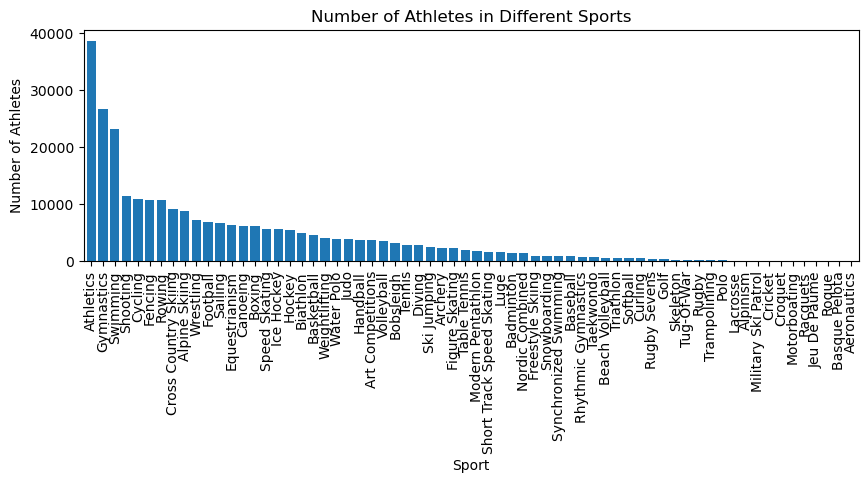

In [44]:
athlete_counts.plot(kind='bar', x='sport', y='name', figsize=(10, 3), width=0.8, rot=90,
                    title='Number of Athletes in Different Sports',
                    xlabel='Sport', ylabel='Number of Athletes', legend=False)

We first filtered the data to include athletes and sports, then counted the number of sports to create a chart.
There are a total of 66 sports. The most popular sports, which have the highest number of athletes,are 
athletics, gymnastics, and swimming. 

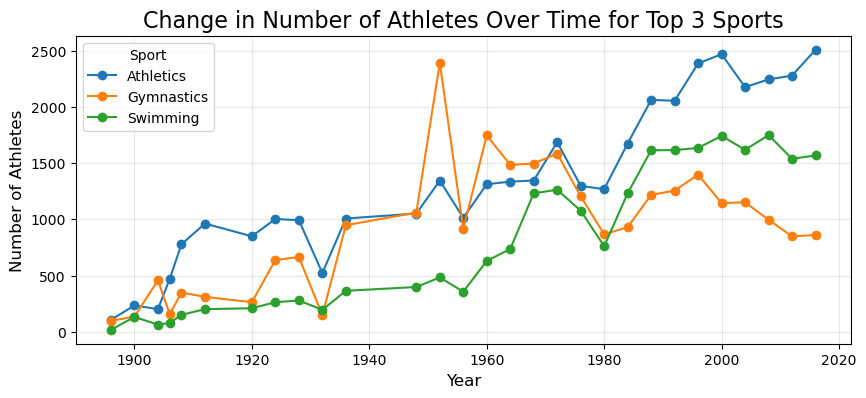

In [46]:
# created a plot
plt.figure(figsize=(10, 4))

for sport in top_sports:
    sport_data = athletes_over_time[athletes_over_time['sport'] == sport]
    plt.plot(sport_data['year'], sport_data['name'], marker='o', label=sport)

plt.title('Change in Number of Athletes Over Time for Top 3 Sports', fontsize=16)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Athletes', fontsize=12)
plt.legend(title='Sport', fontsize=10)
plt.grid(alpha=0.3)
plt.show()

The graph shows the number of athletes over time for Athletics, Gymnastics, and Swimming. Athletics consistently 
has the most participants, steadily growing and peaking at 2500 in later years. Gymnastics shows big changes, 
spiking around 1960 but declining after the 1980s. Swimming starts small but grows steadily from the 1920s, 
leveling off after the 1970s. Drops in all sports during the 1940s (World War II) and late 1970s-1980s suggest 
global disruptions. Overall, participation in these sports has increased over time, with Athletics leading the 
way.

### 4. What is the optimal age for success in various sports, and how does this vary across different athletic disciplines?

In [49]:
# Filter the medalists
medalists_age = olympics[olympics['medal'].notna()]
# Calculate the average age per sport
avg_age_per_sport_year = medalists_age.groupby(['sport'])['age'].mean().round(2).reset_index()
# Get the top 10 sports list
sports_list = olympics['sport'].value_counts().head(10).index.tolist()
# Filter the data for the sports
sports_filtered = avg_age_per_sport_year[avg_age_per_sport_year['sport'].isin(sports_list)]
# Find the year with the optimal age for each sport (highest average age)
optimal_age_per_sport = sports_data.loc[sports_filtered.groupby('sport')['age'].idxmax()]
# Calculate the median age per sport
median_age_per_sport = medalists_age.groupby(['sport', 'year'])['age'].median().round(2).reset_index()
# Filter the data for the sports
sports_data_median = median_age_per_sport[median_age_per_sport['sport'].isin(sports_list)]
# Find the year with the optimal age for each sport (highest average age)
optimal_age_per_sport_median = sports_data_median.loc[sports_data_median.groupby('sport')['age'].idxmax()]

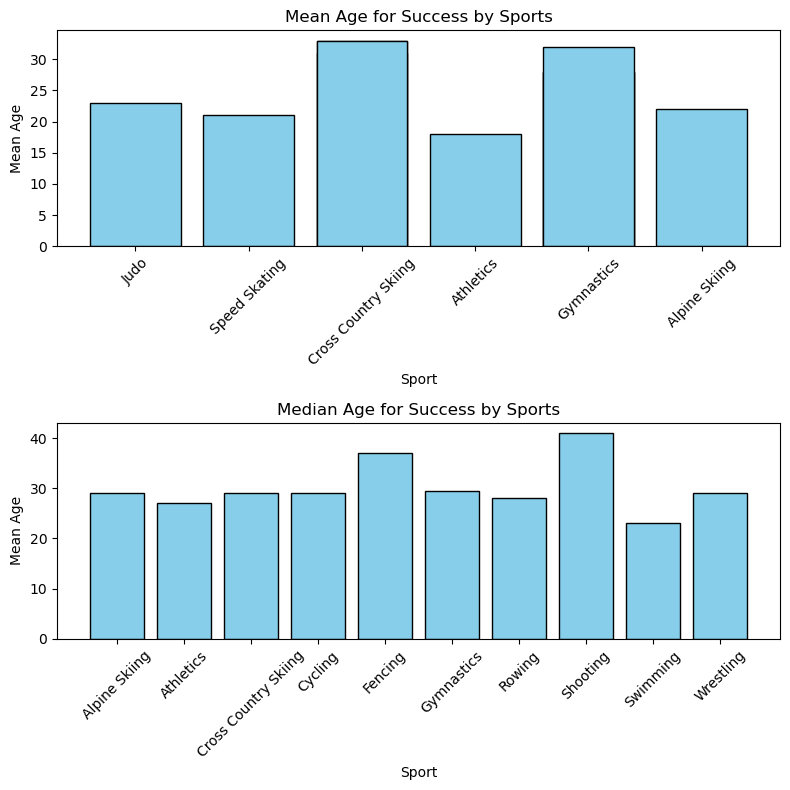

In [50]:
fig, ax = plt.subplots(2, 1, figsize=(8, 8))

# bar plot
ax[0].bar(optimal_age_per_sport['sport'], optimal_age_per_sport['age'], color='skyblue', edgecolor='black')
ax[0].set_title('Mean Age for Success by Sports')
ax[0].set_xlabel('Sport')
ax[0].set_ylabel('Mean Age')
ax[0].tick_params(axis='x', rotation=45)

ax[1].bar(optimal_age_per_sport_median['sport'], optimal_age_per_sport_median['age'], color='skyblue', edgecolor='black')
ax[1].set_title('Median Age for Success by Sports')
ax[1].set_xlabel('Sport')
ax[1].set_ylabel('Mean Age')
ax[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

1. Precision and Strategy-Based Sports (Shooting, Fencing):
   
Trend: Higher mean and median ages for success.
These sports rely heavily on skill, experience, and strategic thinking rather than physical prowess. As a result, athletes can continue to perform well at older ages due to the emphasis on mental focus, timing, and tactical awareness.

2. Physically Demanding and High-Intensity Sports (Gymnastics, Swimming):
   
Trend: Lower mean and median ages for success.
These sports require peak physical fitness, including strength, flexibility, and agility. Athletes typically perform best in their teens and early twenties, as the physical demands of these sports are challenging to maintain beyond that age.

3. Endurance and Mixed-Demand Sports (Cycling, Rowing):
   
Trend: Moderate mean and median ages for success.
These sports blend physical endurance with strategic elements. While younger athletes often have a physical advantage, older athletes can still succeed by leveraging experience, stamina, and tactical knowledge, leading to a broader range of successful ages.


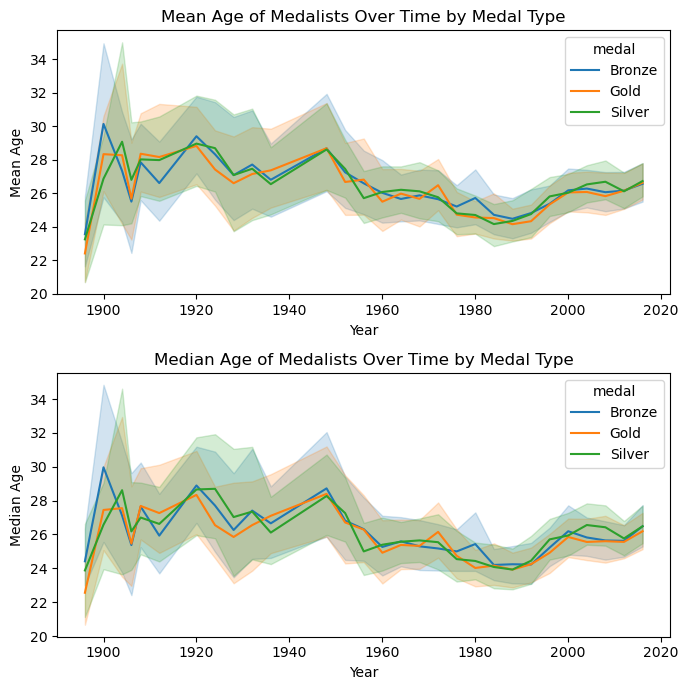

In [52]:
age_stats = medalists.groupby(['medal', 'sport', 'year'])['age'].agg(['mean', 'median']).reset_index()

fig, ax = plt.subplots(2, 1, figsize=(7, 7))

# Visualization 1: Line plot of mean age by year for each medal type
sns.lineplot(data=age_stats, x='year', y='mean', hue='medal', ax=ax[0])
ax[0].set_title('Mean Age of Medalists Over Time by Medal Type')
ax[0].set_xlabel('Year')
ax[0].set_ylabel('Mean Age')

# Visualization 2: Line plot of median age by year for each medal type
sns.lineplot(data=age_stats, x='year', y='median', hue='medal', ax=ax[1])
ax[1].set_title('Median Age of Medalists Over Time by Medal Type')
ax[1].set_xlabel('Year')
ax[1].set_ylabel('Median Age')

plt.tight_layout()
plt.show()

General trend: Most of the medalists' ages fall into the 20-30 year old range.

1. Early Olympics (Pre-1920s)
Both the mean and median ages show high variability in the early years of the Olympics.
The fluctuations suggest inconsistent participation, likely due to smaller athlete pools and fewer events.
Medalists were slightly older on average during this period, as seen in the peaks near the late 1800s and early 1900s.

2. Stabilization and Decline (1920s to 1980s)
From the 1920s onward, there is a downward trend in both mean and median ages, with the trend stabilizing around the mid-20s.
This likely reflects the growing emphasis on athletic specialization, where younger athletes dominated events requiring peak physical performance (e.g., swimming, gymnastics).

3. Modern Olympics (1980s to 2016)
After the 1980s, the trend shows a slight uptick in the ages of medalists across all medal types.
This could be due to advancements in sports science, training, and nutrition, allowing older athletes to remain competitive.
Additionally, some sports (e.g., equestrian, shooting) tend to favor older athletes, potentially influencing the overall trend.

4. Medal Type Differences
The differences between medal types (Gold, Silver, Bronze) are minimal, especially after 1920, indicating that age is not strongly correlated with medal level. All medalists, regardless of the type, generally fall within similar age ranges.